# Customer Churn Prediction

## 1. Business Problem

Customer churn occurs when customers stop using a company's services. Predicting potential churn can help businesses identify customers who may leave and prioritize retention strategies.

## 2. Project Objective

The objective of this project is to develop a machine learning classification model that predicts whether a bank customer is likely to exit based on customer and account-related information.

## 3. Machine Learning Problem

- **Problem type:** Supervised Learning
- **Task:** Binary Classification
- **Target variable:** `Exited`
- **Class 0:** Customer did not exit
- **Class 1:** Customer exited

## 4. Project Workflow

1. Data loading and understanding
2. Exploratory Data Analysis (EDA)
3. Data quality assessment and preprocessing
4. Feature engineering and data splitting
5. Model training and experimentation
6. Model evaluation and comparison
7. Final model selection and saving
8. Conclusions and limitations

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"../Raw/Customer_Churn.csv")

## Data loading and understanding

In [5]:
df.shape

(10025, 18)

In [6]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619.0,France,Female,42.0,2.0,0.0,1,1,1,101348.88,1,1,2.0,DIAMOND,464.0
1,2,15647311,Hill,608.0,Spain,Female,41.0,1.0,83807.86,1,0,1,112542.58,0,1,3.0,DIAMOND,456.0
2,3,15619304,Onio,502.0,France,Female,42.0,8.0,159660.8,3,1,0,113931.57,1,1,3.0,DIAMOND,377.0
3,4,15701354,Boni,699.0,France,Female,39.0,1.0,0.0,2,0,0,93826.63,0,0,5.0,GOLD,350.0
4,5,15737888,Mitchell,850.0,Spain,Female,43.0,2.0,125510.82,1,1,1,79084.1,0,0,5.0,GOLD,425.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10025 entries, 0 to 10024
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10025 non-null  int64  
 1   CustomerId          10025 non-null  int64  
 2   Surname             10025 non-null  str    
 3   CreditScore         9990 non-null   float64
 4    Geography          9979 non-null   str    
 5   Gender              9995 non-null   str    
 6   Age                 9984 non-null   float64
 7   Tenure              9990 non-null   float64
 8   Balance             9975 non-null   str    
 9   NumOfProducts       10025 non-null  int64  
 10  HasCrCard           10025 non-null  int64  
 11  IsActiveMember      10025 non-null  int64  
 12  EstimatedSalary     9980 non-null   str    
 13  Exited              10025 non-null  int64  
 14  Complain            10025 non-null  int64  
 15  Satisfaction Score  10000 non-null  float64
 16  Card Type      

In [8]:
df.isna().sum()

RowNumber              0
CustomerId             0
Surname                0
CreditScore           35
 Geography            46
Gender                30
Age                   41
Tenure                35
Balance               50
NumOfProducts          0
HasCrCard              0
IsActiveMember         0
EstimatedSalary       45
Exited                 0
Complain               0
Satisfaction Score    25
Card Type             35
 Point Earned         30
dtype: int64

In [9]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', ' Geography ',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain',
       'Satisfaction Score', 'Card Type', ' Point Earned '],
      dtype='str')

## Data Standardization

In [10]:
df.columns = df.columns.str.strip()

In [11]:
df.columns = df.columns.str.replace(" ","_")
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
0,1,15634602,Hargrave,619.0,France,Female,42.0,2.0,0.0,1,1,1,101348.88,1,1,2.0,DIAMOND,464.0
1,2,15647311,Hill,608.0,Spain,Female,41.0,1.0,83807.86,1,0,1,112542.58,0,1,3.0,DIAMOND,456.0
2,3,15619304,Onio,502.0,France,Female,42.0,8.0,159660.8,3,1,0,113931.57,1,1,3.0,DIAMOND,377.0
3,4,15701354,Boni,699.0,France,Female,39.0,1.0,0.0,2,0,0,93826.63,0,0,5.0,GOLD,350.0
4,5,15737888,Mitchell,850.0,Spain,Female,43.0,2.0,125510.82,1,1,1,79084.1,0,0,5.0,GOLD,425.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10020,5534,15674765,Mitchell,553.0,Spain,Male,44.0,4.0,0.0,1,1,0,10789.3,0,0,1.0,GOLD,780.0
10021,421,15810418,T'ang,756.0,Germany,Female,60.0,3.0,115924.89,1,1,0,93524.19,1,1,3.0,DIAMOND,523.0
10022,5103,15632899,Nwankwo,662.0,Spain,Male,20.0,9.0,104508.77,2,0,0,73107.53,0,0,5.0,DIAMOND,944.0
10023,7232,15607986,Nnamutaezinwa,555.0,France,Male,40.0,10.0,139930.18,1,1,1,105720.09,0,0,1.0,SILVER,872.0


In [12]:
df_raw = df.copy()

## Removing Uncessary Columns

In [13]:
df = df.drop(columns = ["RowNumber","CustomerId","Surname"])

## Handling Duplicates and Fixing Data Types

In [14]:
df.duplicated().sum()

np.int64(24)

In [15]:
df = df.drop_duplicates()

In [16]:
categorical_cols = ["Geography", "Gender", "Card_Type"]
for column in categorical_cols:
    if column in df.columns:
        df[column] = df[column].astype(str).str.strip().str.title() 



In [17]:
numeric_columns = ["Age","Balance","EstimatedSalary","Point_Earned"]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col],errors = "coerce")
        

## Data Inconsistency Check

In [18]:
df[(df["Age"] <= 0) | (df["Age"] > 120)]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
6190,581.0,Spain,Female,150.0,4.0,170172.90,1,0,1,100236.02,0,0,4.0,Gold,968.0
8304,675.0,France,Male,-2.0,1.0,0.00,2,1,0,157097.09,0,0,2.0,Diamond,526.0
9450,666.0,Germany,Male,0.0,2.0,124125.26,1,1,0,81884.80,0,0,4.0,Silver,459.0


In [19]:
df[(df["Tenure"] < 0) | (df["Tenure"] > 10)]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
282,479.0,Germany,Male,35.0,-1.0,138718.92,1,1,1,47251.79,1,1,1.0,Gold,751.0
341,659.0,France,Male,31.0,15.0,118342.26,1,0,0,161574.19,0,0,3.0,Silver,391.0
9001,688.0,Spain,Male,32.0,99.0,124179.30,1,1,1,138759.15,0,0,1.0,Gold,539.0


In [20]:
for col in ["HasCrCard", "IsActiveMember", "Exited", "Complain"]:
    print(f"\n{col} values:")
    print(df[col].value_counts(dropna=False))


HasCrCard values:
HasCrCard
 1    7055
 0    2944
-1       1
 2       1
Name: count, dtype: int64

IsActiveMember values:
IsActiveMember
 1    5152
 0    4847
 2       1
-1       1
Name: count, dtype: int64

Exited values:
Exited
 0    7962
 1    2037
-1       1
 2       1
Name: count, dtype: int64

Complain values:
Complain
 0    7955
 1    2044
 2       1
-1       1
Name: count, dtype: int64


In [21]:
df[(df["CreditScore"] < 300) | (df["CreditScore"] > 900)]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
4569,9999.0,France,Male,33.0,7.0,115195.58,1,1,1,11205.50,0,0,4.0,Diamond,943.0
8305,-10.0,France,Male,58.0,3.0,0.00,3,1,1,80344.96,1,1,3.0,Silver,488.0
9508,1250.0,NaN,Male,26.0,8.0,96659.64,2,1,1,138775.69,0,0,1.0,Gold,384.0


In [22]:
df[df["NumOfProducts"] <= 0]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
1252,693.0,France,Male,68.0,4.0,97705.99,-1,1,1,61569.07,0,0,1.0,Gold,949.0
5952,590.0,Spain,Male,29.0,10.0,0.00,0,1,1,51907.72,1,1,1.0,Gold,523.0


In [23]:
df[df["EstimatedSalary"] < 0]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
4269,748.0,France,Male,44.0,4.0,112610.77,1,0,1,-1.0,0,0,3.0,Gold,315.0
7435,610.0,NaN,Female,50.0,5.0,130554.51,3,1,0,-5000.0,1,1,2.0,Silver,821.0


In [24]:
df.loc[df["Point_Earned"] > 1000]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned
925,714.0,Germany,Female,36.0,1.0,101609.01,2,1,1,447.73,0,0,3.0,Platinum,1500.0
4058,557.0,France,Male,39.0,8.0,146200.01,1,1,0,177944.64,0,0,2.0,Gold,9999.0


## Handling Missing values and Inconsistant values for visualization purpose

In [25]:
df.loc[(df["Age"]<=0) | (df["Age"]>120),"Age"] = np.nan

df.loc[(df["Tenure"]<0) | (df["Tenure"]>10),"Tenure"] = np.nan

df.loc[(df["CreditScore"]<300) | (df["CreditScore"]>900),"CreditScore"] = np.nan

df.loc[df["NumOfProducts"]<=0, "NumOfProducts" ] = np.nan

df.loc[df["EstimatedSalary"] < 0, "EstimatedSalary"] = np.nan

df.loc[df["Point_Earned"] > 1000, "Point_Earned"] = np.nan


In [26]:
binary_cols = ["HasCrCard","IsActiveMember","Exited","Complain"]

for col in binary_cols :
    df.loc[~df[col].isin([0,1]) & df[col].notna(),col] = np.nan 

In [ ]:
df = df.dropna(subset=['Exited'])
df['Exited'] = df['Exited'].astype(int)

In [27]:
numeric_columns = [
    "Age", "Tenure", "CreditScore",
    "NumOfProducts", "EstimatedSalary", "Balance",
    "Satisfaction_Score", "Point_Earned"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())



In [28]:
categorical_cols = ["Geography", "Gender", "Card_Type"]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

binary_cols = ["HasCrCard", "IsActiveMember", "Complain"]

for col in binary_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

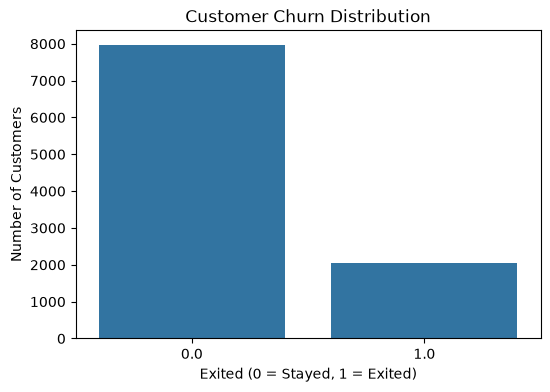


Target percentages:
Exited
0.0    79.61
1.0    20.37
NaN     0.02
Name: proportion, dtype: float64


In [42]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Exited")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Exited)")
plt.ylabel("Number of Customers")
plt.show()

print("\nTarget percentages:")
print((df["Exited"].value_counts(normalize=True, dropna=False) * 100).round(2))

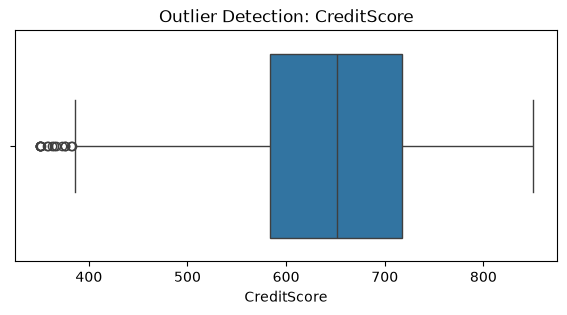

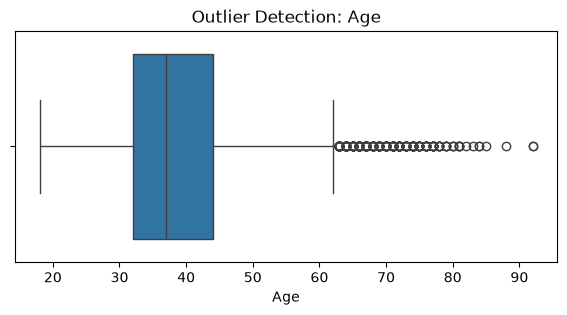

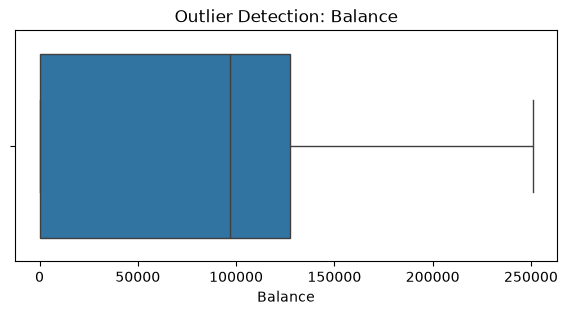

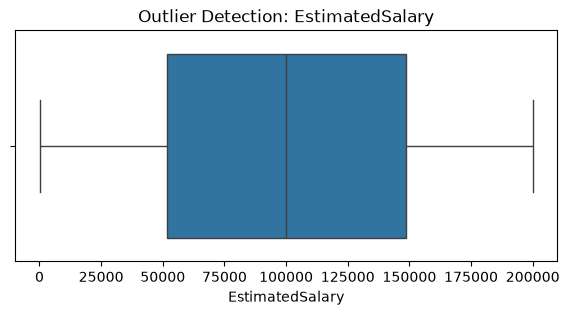

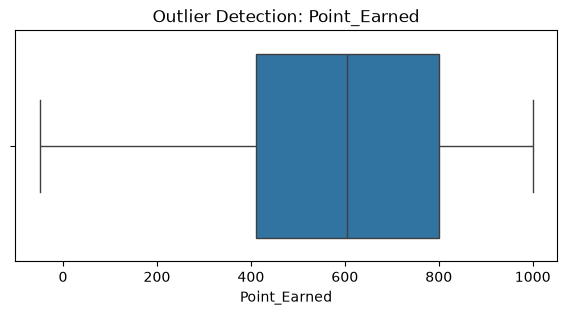

In [43]:
numeric_cols = [
    "CreditScore",
    "Age",
    "Balance",
    "EstimatedSalary",
    "Point_Earned"
]

for col in numeric_cols:
    if col in df.columns:
        plt.figure(figsize=(7, 3))
        sns.boxplot(x=df[col])
        plt.title(f"Outlier Detection: {col}")
        plt.show()

In [44]:
for col in numeric_cols:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        count = ((df[col] < lower) | (df[col] > upper)).sum()

        print(f"{col}: {count} potential outliers")

CreditScore: 16 potential outliers
Age: 355 potential outliers
Balance: 0 potential outliers
EstimatedSalary: 0 potential outliers
Point_Earned: 0 potential outliers


* Age has 355 outlier primarily skewed toward older age groups (> 60 years old).

# Uni Variate Analysis

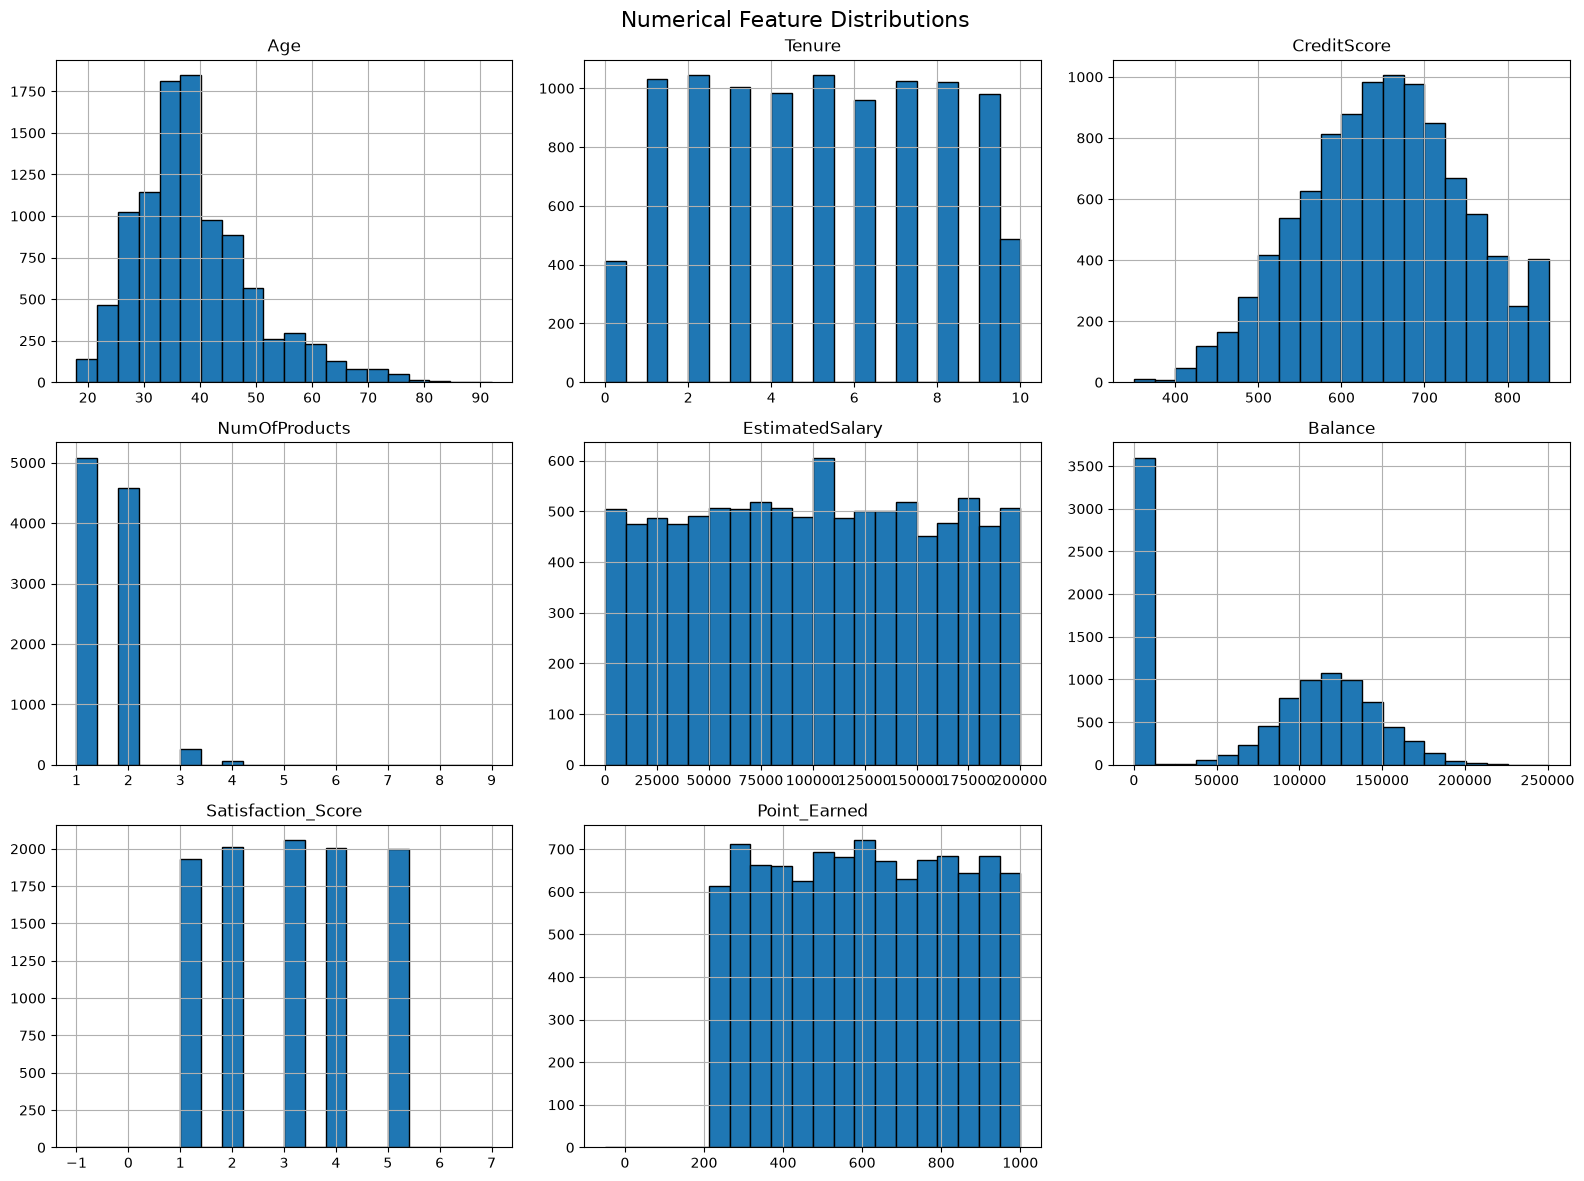

In [30]:
df[numeric_columns].hist(figsize=(16, 12),
    bins=20,edgecolor = "Black")
plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

* Age category is skewed
* High concentration of Zero-Balance Account
* Is_Zero_Balance can be considered for feature engineering

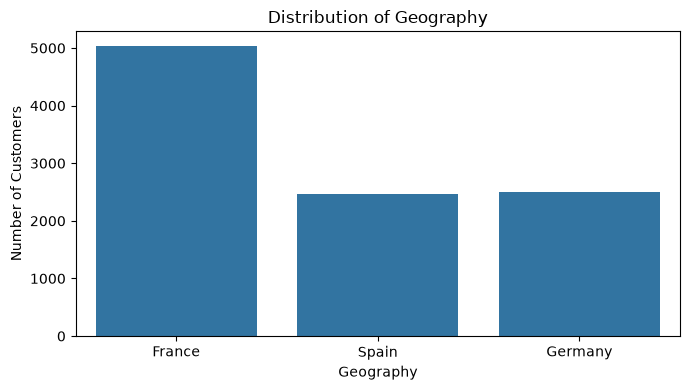

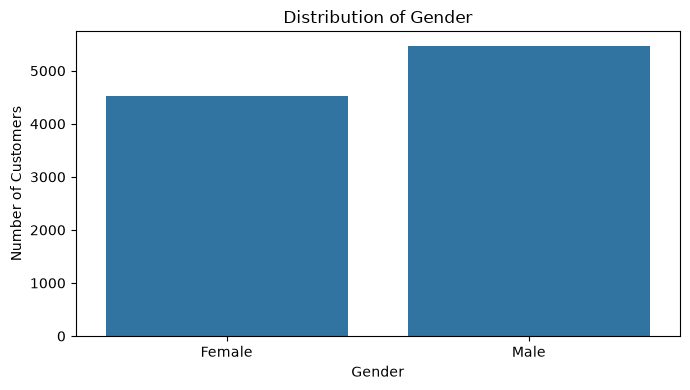

In [31]:
for col in "Geography","Gender":
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.tight_layout()
    plt.show()

* France has more number of customers
* There are more Male category in the number of customers

## Bi variate Analysis

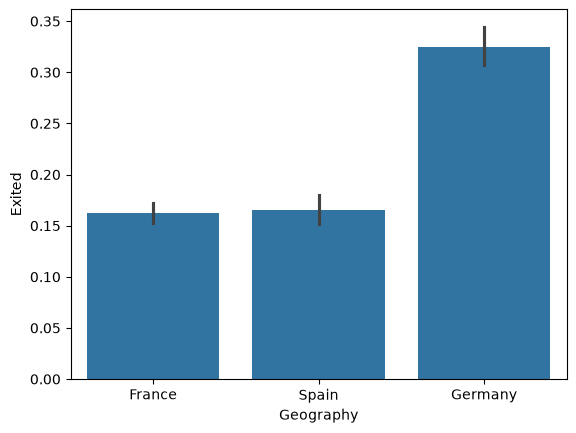

In [32]:
sns.barplot(data=df,x = "Geography",y="Exited")
plt.show()

* Germany has high churn rate 

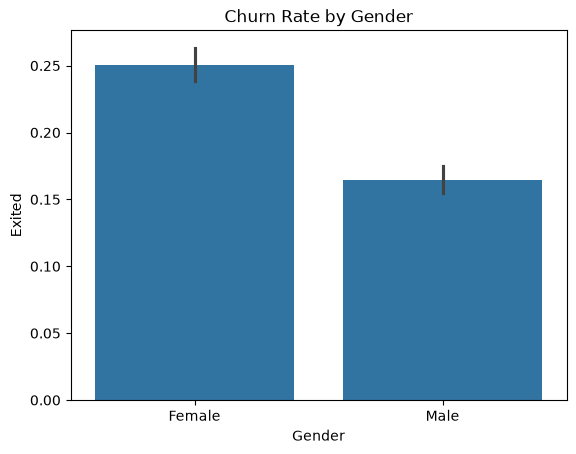

In [33]:
sns.barplot(data=df, x="Gender", y="Exited")
plt.title("Churn Rate by Gender")
plt.show()

* female customers are exiting at a higher rate.

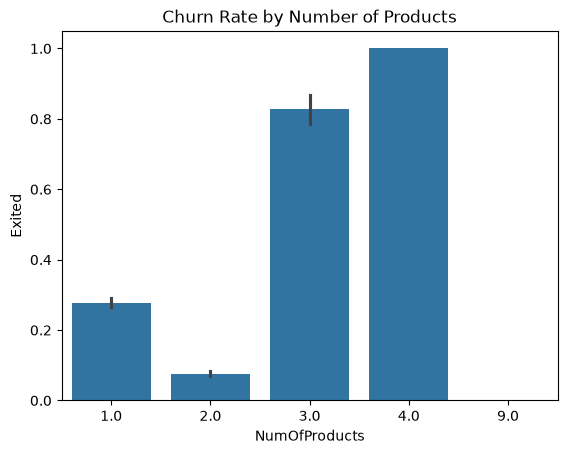

In [34]:
sns.barplot(data=df, x="NumOfProducts", y="Exited")
plt.title("Churn Rate by Number of Products")
plt.show()

* customers with 3 or 4 products often have dramatically higher churn rates compared to those with 2 products.

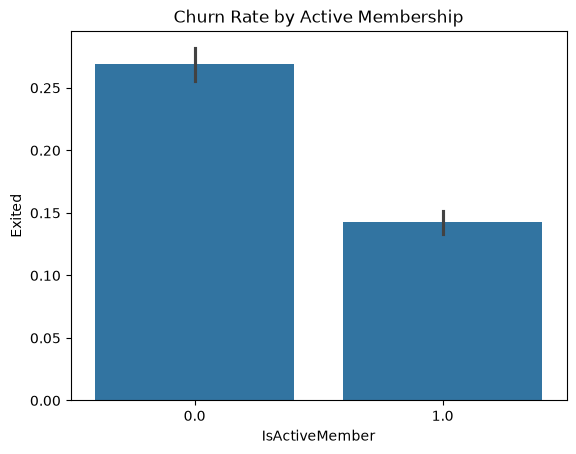

In [35]:
sns.barplot(data=df, x="IsActiveMember", y="Exited")
plt.title("Churn Rate by Active Membership")
plt.show()

* There are high rate of inactive customers who have exited

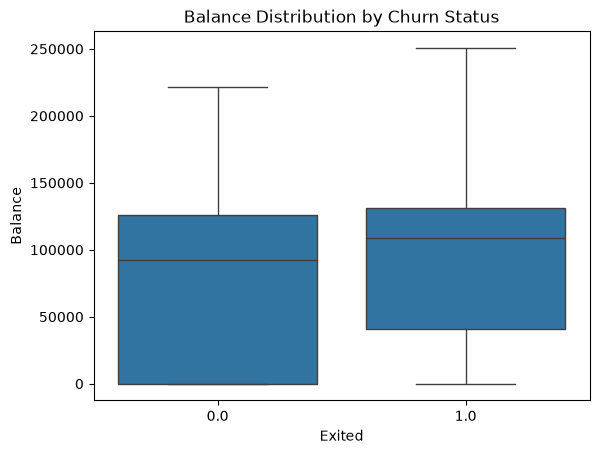

In [37]:
sns.boxplot(data=df, x="Exited", y="Balance")
plt.title("Balance Distribution by Churn Status")
plt.show()

* The bank is losing customers who carry higher capital than low-balance customers
* A massive portion of non-churned customers hold a 0 balance with the bank. In contrast, customers who actively churn tend to have non-zero, active balances.

C:\Users\Zafeer\AppData\Local\Temp\ipykernel_9656\196692889.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x="Age", hue="Exited", common_norm=False, shade=True)


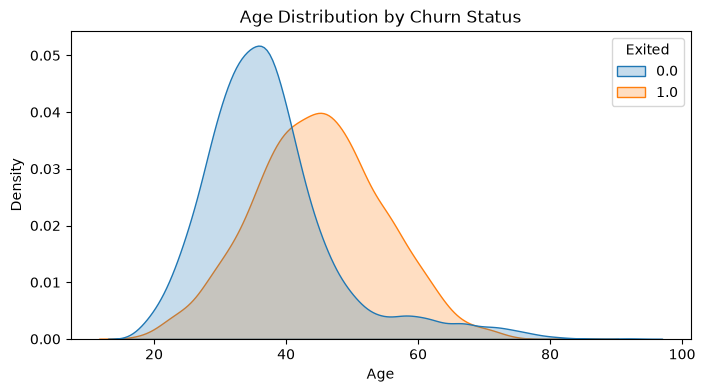

In [38]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="Age", hue="Exited", common_norm=False, shade=True)
plt.title("Age Distribution by Churn Status")
plt.show()

* customers who didnt churn highly is in the age range of 35 - 40 
* While the bulk of younger customers tend to stay, the distribution for churned customers stretches much further into the higher age brackets (50–70+ years old) 
* This distinct separation between the two curves shows that Age is a strong, non-linear predictor for customer churn
* Age bining can be considered for feature engineering

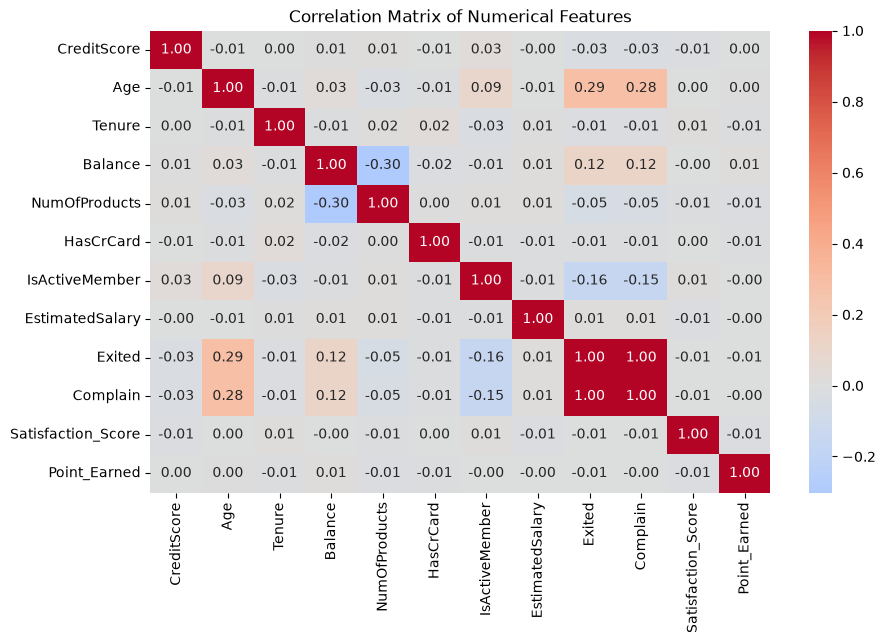

In [45]:
df_corr = df.corr(numeric_only = True)

plt.figure(figsize=(10, 6))
sns.heatmap(df_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

* There is a notable inverse relationship ($-0.30$) between the customer's account balance and the number of bank products they hold
* Customers with higher account balances tend to hold fewer products, whereas customers with more products (e.g., 3 or 4) hold lower or zero account balances.
* whereas customers with more products (e.g., 3 or 4) hold lower or zero account balances.
* Product_Risk_Flag can be considered Since holding 3 or 4 products correlates strongly with extreme churn rates, create a flag highlighting high-product customers.

# Insights 

## Target Class Imbalance

* Churn rate sits at 20.37% Exited (Class 1) versus 79.61% Retained (Class 0).
* Accuracy alone will be misleading. Model evaluation should prioritize Recall, Precision, F1-Score, and ROC-AUC, or leverage class weighting / SMOTE.

## Geographic & Demographic Patterns

* Germany exhibits a churn rate of over 32%, double that of France (~16%) and Spain (~16%).
* Non-churned customers peak between 35–40 years old, whereas churned customers peak around 45–50 years old with higher tail representation (50–70+ years).
* Female customers exhibit a higher churn rate compared to male customers.

## Behavioral & Product Usage Trends

* Customers holding 3 or 4 products face extreme churn rates compared to those holding 1 or 2 products.
* Inactive members (IsActiveMember = 0) exit at a significantly higher rate than active members.

## Financial & Balance Behavior

* The median account balance of churned customers is higher than that of retained customers, meaning churn directly threatens high-capital accounts.
* Retained customers comprise a huge concentration of $0 balance accounts, whereas churned customers almost exclusively have active, positive balances.
* A moderate inverse relationship (-0.30) exists between Balance and NumOfProducts—customers with higher balances hold fewer products.

## Possible Feature Engineering

* Is_Zero_Balance (Binary flag)
* Age_Group (binning)
* Balance_to_salary (financial leverage ratio)
* Product_Risk_Flag(Binary indicator for high-product)